# OLIST E-COMMERCE DATASET - Dataset Analysis
## Week 1 : Data Science Internship
1. Objective : To analyze the Olist Brazilian E-Commerce Dataset while documenting KPI summary and trend analysis.
2. Data Loading and Validation
3. Key Performance Indicators (KPIs)
4. Monthly Sales Trend Analysis
5. Product and Category Performance
6. Customer Insights
7. Regional Sales Analysis
8. Delivery Performance Analysis
9. Key Business Findings
10. Conclusion and Recommendations

### 1. Objective : To analyze the Olist Brazilian E-Commerce Dataset while documenting KPI summary and trend analysis.


### 2. Data Loading and Validation

In [1]:
# Data loading and validation

from pathlib import Path 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("G:\\My Drive\\data_science_week1_assignment\\01_data\\02_cleaned_data")

orders = pd.read_csv(
    DATA_DIR/"orders.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"

    ]
)

order_items = pd.read_csv(DATA_DIR / "order_items.csv")
order_payments = pd.read_csv(DATA_DIR / "order_payments.csv")
order_reviews = pd.read_csv(DATA_DIR / "order_reviews.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
customers = pd.read_csv(DATA_DIR / "customers.csv")
sellers = pd.read_csv(DATA_DIR / "sellers.csv")
category_translation = pd.read_csv(
    DATA_DIR / "product_category_name_translation.csv"
)

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Payments:", order_payments.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)

Orders: (99441, 8)
Order items: (112650, 7)
Payments: (103886, 5)
Products: (32951, 9)
Customers: (99441, 5)


### 3. Key performance Indicators(KPIs)

In [2]:
# select delivered orders for the initial completed-sales analysis

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Total orders in dataset:", orders["order_id"].nunique())
print("Delivered orders:", delivered_orders["order_id"].nunique())

Total orders in dataset: 99441
Delivered orders: 96478


In [3]:
# Keeping items belonging to delivered orders

delivered_items = order_items.merge(
    delivered_orders[["order_id"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

print("Delivered order items:", len(delivered_items))

Delivered order items: 110197


In [4]:
# Core sales KPIs

total_revenue = delivered_items["price"].sum()

total_orders = delivered_orders["order_id"].nunique()

average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else 0
)

total_units_sold = delivered_items["order_item_id"].count()

kpi_summary = pd.DataFrame({
    "KPI":[
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold"
    ],
    "Value":[
        total_revenue,
        total_orders,
        average_order_value,
        total_units_sold
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Revenue,1.322150e+07
1,Total Orders,9.647800e+04
2,Average Order Value,1.370416e+02
3,Total Units Sold,1.101970e+05


In [5]:
# Adding english category names to product records

products_eng = products.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

products_eng["category_name_english"] = (
    products_eng["product_category_name_english"]
    .fillna("Unknown/Untranslated")
)

# Attaching product and category information to delivered items

sales_items = delivered_items.merge(
    products_eng[
        ["product_id","category_name_english"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

sales_items["category_name_english"] = (
    sales_items["category_name_english"]
    .fillna("Unknown / Untranslated")
)

print("Sales item rows:", len(sales_items))

Sales item rows: 110197


In [6]:
# Top revenue-generating category

category_sales = (
    sales_items.groupby("category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        units_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue",ascending=False)
    .reset_index()
)

display(category_sales.head(10))

,category_name_english,total_revenue,units_sold,unique_orders
0,health_beauty,1233131.72,9465,8647
1,watches_gifts,1166176.98,5859,5495
2,bed_bath_table,1023434.76,10953,9272
3,sports_leisure,954852.55,8431,7530
4,computers_accessories,888724.61,7644,6530
5,furniture_decor,711927.69,8160,6307
6,housewares,615628.69,6795,5743
7,cool_stuff,610204.10,3718,3559
8,auto,578966.65,4140,3810
9,toys,471286.48,4030,3804


In [7]:
# Top revenue-generating product

product_sales = (
    sales_items.groupby("product_id")
    .agg(
        total_revenue=("price", "sum"),
        units_sold=("order_item_id", "count"),
        unique_orders=("order_id", "nunique")
    )
    .sort_values("total_revenue", ascending=False)
    .reset_index()
)

display(product_sales.head(10))

,product_id,total_revenue,units_sold,unique_orders
0,bb50f2e236e5eea0100680137654686c,63560.00,194,186
1,6cdd53843498f92890544667809f1595,53652.30,153,148
2,d6160fb7873f184099d9bc95e30376af,45949.35,33,33
3,d1c427060a0f73f6b889a5c7c61f2ac4,45620.56,332,313
4,99a4788cb24856965c36a24e339b6058,42049.66,477,456
5,3dd2a17168ec895c781a9191c1e95ad7,40782.80,272,253
6,25c38557cf793876c5abdd5931f922db,38907.32,38,38
7,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63,63
8,53b36df67ebb7c41585e8d54d6772e08,37454.63,321,304
9,aca2eb7d00ea1a7b8ebd4e68314663af,37104.30,520,425


In [8]:
# Identify the top-selling category by revenue
top_category = category_sales.iloc[0]["category_name_english"]

# Identify the top revenue-generating product
top_product = product_sales.iloc[0]["product_id"]

# Create the complete KPI summary
kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top-Selling Category",
        "Top Revenue-Generating Product"
    ],
    "Value": [
        f"R$ {total_revenue:,.2f}",
        f"{total_orders:,}",
        f"R$ {average_order_value:,.2f}",
        f"{total_units_sold:,}",
        top_category,
        top_product
    ]
})

display(kpi_summary)


,KPI,Value
0,Total Revenue,"R$ 13,221,498.11"
1,Total Orders,"96,478"
2,Average Order Value,R$ 137.04
3,Total Units Sold,"110,197"
4,Top-Selling Category,health_beauty
5,Top Revenue-Generating Product,bb50f2e236e5eea0100680137654686c


### Key KPI Analysis

The initial KPI analysis provides an overview of Olist's e-commerce performance. Revenue, order volume, average order value, and units sold help measure overall sales activity, while category and product performance identify the main contributors to product revenue.

1. **Total Revenue:** Measures the total value of products sold in delivered orders. Freight charges are excluded from this calculation.

2. **Total Orders:** Measures the number of unique delivered orders, providing an overview of successfully completed customer purchases.

3. **Average Order Value (AOV):** Represents the average product revenue per delivered order. It is calculated by dividing total product revenue by the number of unique delivered orders.

4. **Total Units Sold:** Measures the number of order-item records associated with delivered orders. Each record represents an item line in an order.

5. **Top-Selling Category:** Identifies the product category generating the highest revenue among delivered orders. This helps highlight the strongest category by sales value.

6. **Top Revenue-Generating Product:** Identifies the product contributing the highest revenue among delivered orders. The product is represented by its product ID because descriptive product names are not available in the dataset.

These KPIs provide a baseline for further analysis of monthly sales trends, product category performance, customer purchasing behavior, regional sales, and delivery performance.


### 4. Monthly Trend Analysis

In [9]:
# Attaching purchase date to the sales item records
# Check whether the purchase timestamp already exists
if "order_purchase_timestamp" not in sales_items.columns:
    sales_items = sales_items.merge(
        delivered_orders[["order_id", "order_purchase_timestamp"]],
        on="order_id",
        how="left",
        validate="many_to_one"
    )

# Extract year and month
sales_items["purchase_month"] = (
    sales_items["order_purchase_timestamp"].dt.to_period("M")
)

# Calculate monthly sales
monthly_sales = (
    sales_items.groupby("purchase_month")
    .agg(
        monthly_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        units_sold=("order_item_id", "count")
    )
    .reset_index()
    .sort_values("purchase_month")
)

# Format the month for display
monthly_sales["purchase_month"] = (
    monthly_sales["purchase_month"].astype(str)
)

display(monthly_sales)



,purchase_month,monthly_revenue,total_orders,units_sold
0,2016-09,134.97,1,3
1,2016-10,40325.11,265,313
2,2016-12,10.90,1,1
3,2017-01,111798.36,750,913
4,2017-02,234223.40,1653,1858
5,2017-03,359198.85,2546,2897
6,2017-04,340669.68,2303,2569
7,2017-05,489338.25,3546,4004
8,2017-06,421923.37,3135,3489
9,2017-07,481604.52,3872,4416


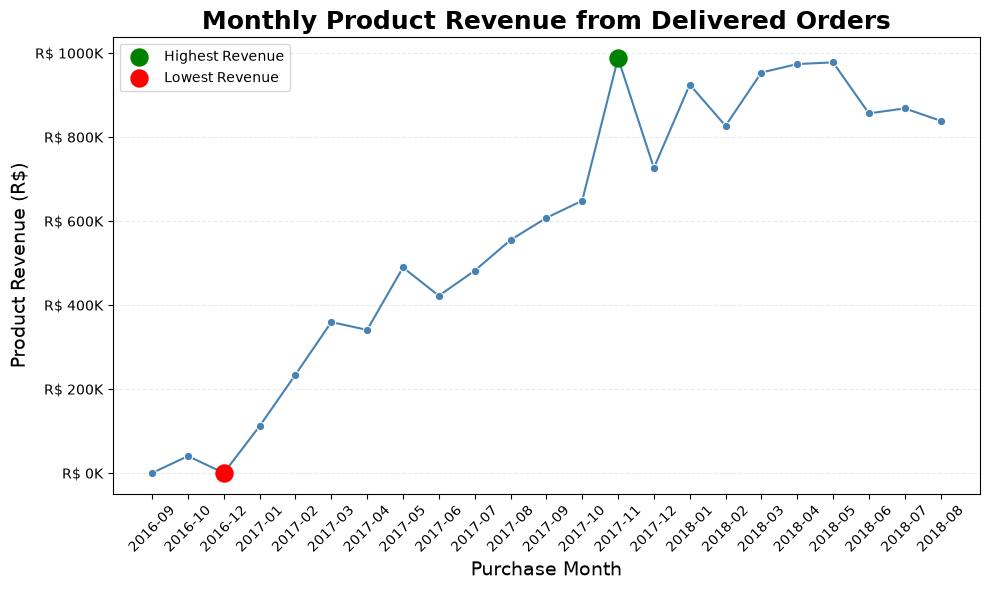

Highest revenue: 2017-11 (R$ 987,765.37)
Lowest revenue: 2016-12 (R$ 10.90)


In [10]:
# Visualizing monthly sales trends

# Find the months with the highest and lowest revenue
max_idx = monthly_sales["monthly_revenue"].idxmax()
min_idx = monthly_sales["monthly_revenue"].idxmin()

highest_month = monthly_sales.loc[max_idx]
lowest_month = monthly_sales.loc[min_idx]

plt.figure(figsize=(10, 6))

# Draw the monthly revenue trend
ax = sns.lineplot(
    data=monthly_sales,
    x="purchase_month",
    y="monthly_revenue",
    marker="o",
    color="steelblue"
)

# Highlight the highest value in green
plt.scatter(
    highest_month["purchase_month"],
    highest_month["monthly_revenue"],
    color="green",
    s=150,
    zorder=5,
    label="Highest Revenue"
)

# Highlight the lowest value in red
plt.scatter(
    lowest_month["purchase_month"],
    lowest_month["monthly_revenue"],
    color="red",
    s=150,
    zorder=5,
    label="Lowest Revenue"
)

plt.title(
    "Monthly Product Revenue from Delivered Orders",
    fontsize=18,
    fontweight="bold"
)
plt.xlabel("Purchase Month", fontsize=14)
plt.ylabel("Product Revenue (R$)", fontsize=14)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.25)

# Format y-axis in thousands (K)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"R$ {x / 1_000:.0f}K")
)

plt.legend()
plt.tight_layout()
plt.show()

# Print the highest and lowest revenue months
print(
    f"Highest revenue: {highest_month['purchase_month']} "
    f"(R$ {highest_month['monthly_revenue']:,.2f})"
)
print(
    f"Lowest revenue: {lowest_month['purchase_month']} "
    f"(R$ {lowest_month['monthly_revenue']:,.2f})"
)


### Key Insights: Monthly Sales Trends

1. **Peak Revenue in November 2017:** November 2017 recorded the highest monthly product revenue at **R$ 987,765.37**, generated from 7,289 delivered orders and 8,475 units sold. This was the strongest month in the analyzed dataset by product revenue.

2. **Strong Sales in April and May 2018:** April 2018 generated R$ 973,534.09, while May 2018 generated R$ 977,544.69. Both months performed close to the November 2017 peak, indicating consistently high revenue during this period.

3. **Revenue and Order Volume:** November 2017 had the highest revenue and also recorded more orders and units sold than either April or May 2018. This suggests that its revenue performance was supported by a higher volume of delivered orders and items.

4. **Very Low Revenue at the Beginning of the Dataset:** December 2016 recorded only R$ 10.90 from one order and one item, while September 2016 recorded R$ 134.97 from one order and three items. These unusually low figures may reflect limited data coverage during the early months rather than normal business performance.

5. **Growth in Recorded Sales Activity:** Revenue increased from R$ 40,325.11 in October 2016 to nearly R$ 1 million in November 2017. This shows a substantial increase in recorded monthly sales, although the early months' low order counts mean the comparison should be interpreted cautiously.

6. **Business Implication:** The strongest revenue months provide useful periods for investigating product category performance, order volumes, and customer purchasing patterns. Understanding what contributed to these peaks could help inform inventory and sales planning.


### 5. Product and Category Performance

5.1 Find the top 10 revenue-generating categories

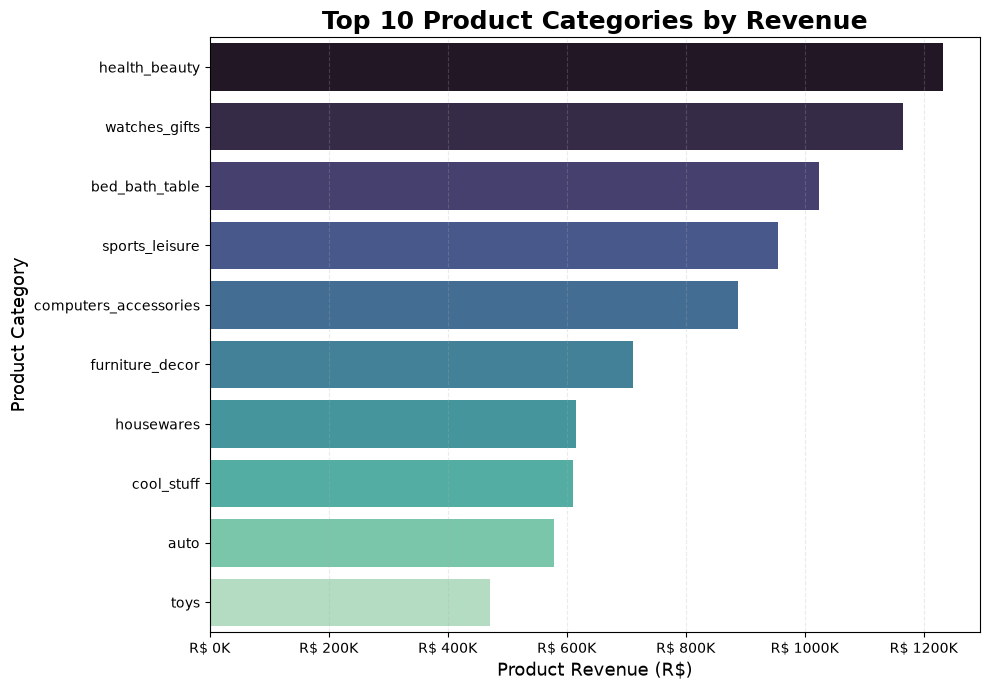

,category_name_english,total_revenue,units_sold,unique_orders
0,health_beauty,1233131.72,9465,8647
1,watches_gifts,1166176.98,5859,5495
2,bed_bath_table,1023434.76,10953,9272
3,sports_leisure,954852.55,8431,7530
4,computers_accessories,888724.61,7644,6530
5,furniture_decor,711927.69,8160,6307
6,housewares,615628.69,6795,5743
7,cool_stuff,610204.10,3718,3559
8,auto,578966.65,4140,3810
9,toys,471286.48,4030,3804


In [11]:
# Top 10 categories by product revenue

top_categories = (
    category_sales
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_categories,
    x="total_revenue",
    y="category_name_english",
    hue="category_name_english",
    palette="mako",
    legend=False
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=18,
    fontweight="bold"
)
plt.xlabel("Product Revenue (R$)", fontsize=13)
plt.ylabel("Product Category", fontsize=13)

ax = plt.gca()
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"R$ {x / 1_000:.0f}K")
)

plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()
top_categories


5.2 — Find the top 10 categories by units sold

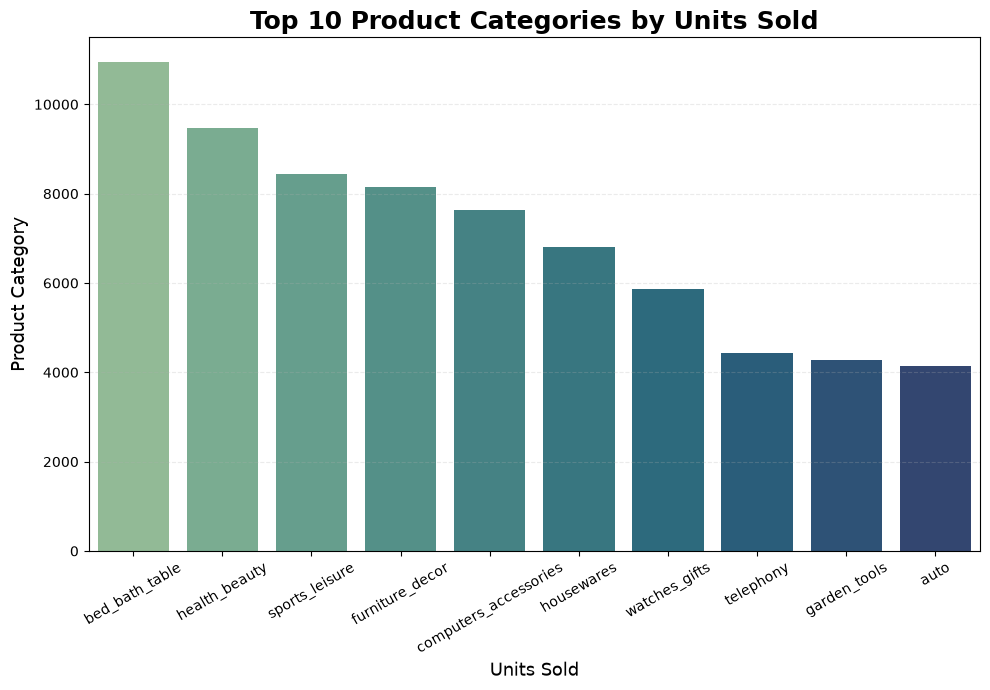

,category_name_english,total_revenue,units_sold,unique_orders
2,bed_bath_table,1023434.76,10953,9272
0,health_beauty,1233131.72,9465,8647
3,sports_leisure,954852.55,8431,7530
5,furniture_decor,711927.69,8160,6307
4,computers_accessories,888724.61,7644,6530
6,housewares,615628.69,6795,5743
1,watches_gifts,1166176.98,5859,5495
13,telephony,309860.23,4430,4093
10,garden_tools,470495.28,4268,3448
8,auto,578966.65,4140,3810


In [12]:
# Top 10 categories by units sold

top_categories_units = (
    category_sales
    .sort_values("units_sold", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_categories_units,
    y="units_sold",
    x="category_name_english",
    hue="category_name_english",
    palette="crest",
    legend=False
)

plt.title(
    "Top 10 Product Categories by Units Sold",
    fontsize=18,
    fontweight="bold"
)
plt.xlabel("Units Sold", fontsize=13)
plt.ylabel("Product Category", fontsize=13)

plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()
top_categories_units

5.3 — Identify the top 10 products by revenue

In [13]:
# Top 10 products by revenue
top_products = (
    product_sales
    .sort_values("total_revenue", ascending=False)
    .head(10)
    .copy()
)
top_products["average_revenue_per_unit"] = (
    top_products["total_revenue"] / top_products["units_sold"]
)
top_product_details = (
    top_products
    .merge(
        products_eng[
            [
                "product_id",
                "category_name_english",
                "product_category_name",
                "product_name_lenght",
                "product_description_lenght"
            ]
        ],
        on="product_id",
        how="left",
        validate="one_to_one"
    )
)

display(top_product_details)


,product_id,total_revenue,units_sold,unique_orders,average_revenue_per_unit,category_name_english,product_category_name,product_name_lenght,product_description_lenght
0,bb50f2e236e5eea0100680137654686c,63560.00,194,186,327.628866,health_beauty,beleza_saude,60.0,2644.0
1,6cdd53843498f92890544667809f1595,53652.30,153,148,350.668627,health_beauty,beleza_saude,51.0,625.0
2,d6160fb7873f184099d9bc95e30376af,45949.35,33,33,1392.404545,computers,pcs,55.0,3632.0
3,d1c427060a0f73f6b889a5c7c61f2ac4,45620.56,332,313,137.411325,computers_accessories,informatica_acessorios,59.0,1893.0
4,99a4788cb24856965c36a24e339b6058,42049.66,477,456,88.154423,bed_bath_table,cama_mesa_banho,54.0,245.0
5,3dd2a17168ec895c781a9191c1e95ad7,40782.80,272,253,149.936765,computers_accessories,informatica_acessorios,48.0,894.0
6,25c38557cf793876c5abdd5931f922db,38907.32,38,38,1023.876842,baby,bebes,58.0,1447.0
7,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63,63,598.950794,cool_stuff,cool_stuff,38.0,1176.0
8,53b36df67ebb7c41585e8d54d6772e08,37454.63,321,304,116.681090,watches_gifts,relogios_presentes,33.0,523.0
9,aca2eb7d00ea1a7b8ebd4e68314663af,37104.30,520,425,71.354423,furniture_decor,moveis_decoracao,44.0,903.0


### Key Insights: Top performing categories 
1. **Top revenue category**: Health & Beauty, at approximately R$1.23 million.
2. **Top category by units sold**: Bed, Bath & Table, with 10,953 units.
3. **Top revenue-generating product**: Product bb50f2e236e5eea0100680137654686c, generating R$63,560.
4. **Key pattern**: Categories and products with the highest revenue do not necessarily have the highest sales volume.

### Key Insights: Top performing and products
1. **Health & Beauty** had the two highest-revenue individual products in the top 10.
2. **A Computers product** generated nearly R$46,000 from just 33 units, suggesting a high average selling price.
3. **Furniture & Decor** recorded the highest unit count among the listed products, with 520 units sold.
4. **Revenue and sales** volume did not always move together, so both metrics are important for evaluating product performance.

### 6. Customer Insights

6.1 Most Frequent orders from different customer segment

In [14]:
# Merge the customer information

delivered_orders_customer = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Total delivered orders:", len(delivered_orders_customer))
print(
    "Unique customers:",
    delivered_orders_customer["customer_unique_id"].nunique()
)
print(
    "Missing customer IDs:",
    delivered_orders_customer["customer_unique_id"].isna().sum()
)

# Count delivered orders per unique customer
customer_order_counts = (
    delivered_orders_customer
    .groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index(name="order_count")
)

# Classify customers by purchase frequency
customer_order_counts["customer_segment"] = np.where(
    customer_order_counts["order_count"] == 1,
    "One-Time Customer",
    "Repeat Customer"
)

# Summarize each customer segment
customer_segment_summary = (
    customer_order_counts
    .groupby("customer_segment")
    .agg(
        total_customers=("customer_unique_id", "nunique"),
        total_orders=("order_count", "sum")
    )
    .reset_index()
)

# Calculate percentage of total customers
customer_segment_summary["customer_percentage"] = (
    customer_segment_summary["total_customers"]
    / customer_segment_summary["total_customers"].sum()
    * 100
)

display(customer_segment_summary.round(2))

Total delivered orders: 96478
Unique customers: 93358
Missing customer IDs: 0


,customer_segment,total_customers,total_orders,customer_percentage
0,One-Time Customer,90557,90557,97.0
1,Repeat Customer,2801,5921,3.0


6.2 Which region or city shows high order density

In [15]:
# Attach customer location to the delivered ordes customer records

regional_orders = delivered_orders_customer.merge(
    customers[
    ["customer_id","customer_state","customer_city"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Summarize delivered orders by state
state_order_summary=(
    regional_orders
    .groupby(["customer_state","customer_city"])
    .agg(
        total_orders=("order_id","nunique"),
        total_customers=("customer_unique_id","nunique")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

state_order_summary["order_percentage"] = (
    state_order_summary["total_orders"]
    / state_order_summary["total_orders"].sum()
    *100
)

display(state_order_summary.head(10).round(2))

,customer_state,customer_city,total_orders,total_customers,order_percentage
4138,SP,sao paulo,15045,14528,15.59
2763,RJ,rio de janeiro,6601,6361,6.84
1053,MG,belo horizonte,2697,2606,2.80
598,DF,brasilia,2071,2013,2.15
2387,PR,curitiba,1489,1434,1.54
3692,SP,campinas,1406,1363,1.46
3177,RS,porto alegre,1342,1292,1.39
369,BA,salvador,1188,1154,1.23
3799,SP,guarulhos,1144,1111,1.19
4122,SP,sao bernardo do campo,911,881,0.94


6.3 Are some product categories preferred by specific customer groups?

In [16]:
# Add customer identifiers to delivered order items
category_customer_data = sales_items.merge(
    delivered_orders_customer[["order_id", "customer_unique_id"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Attach customer segments to category-level purchase data
category_customer_data = category_customer_data.merge(
    customer_order_counts[
        ["customer_unique_id", "customer_segment"]
    ],
    on="customer_unique_id",
    how="left",
    validate="many_to_one"
)

# Summarize category performance by customer segment
category_preferences = (
    category_customer_data
    .groupby(["customer_segment", "category_name_english"])
    .agg(
        units_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        unique_orders=("order_id", "nunique")
    )
    .reset_index()
)

# Show the top five categories for each segment by revenue
top_categories_by_segment = (
    category_preferences
    .sort_values(
        ["customer_segment", "revenue"],
        ascending=[True, False]
    )
    .groupby("customer_segment")
    .head(5)
)

display(top_categories_by_segment)

,customer_segment,category_name_english,units_sold,revenue,unique_orders
44,One-Time Customer,health_beauty,8936,1178668.42,8162
71,One-Time Customer,watches_gifts,5547,1113974.03,5222
8,One-Time Customer,bed_bath_table,9880,928596.33,8430
66,One-Time Customer,sports_leisure,7791,883594.42,6955
16,One-Time Customer,computers_accessories,7116,828147.53,6135
80,Repeat Customer,bed_bath_table,1073,94838.43,842
135,Repeat Customer,sports_leisure,640,71258.13,575
110,Repeat Customer,furniture_decor,798,62158.94,574
87,Repeat Customer,computers_accessories,528,60577.08,395
114,Repeat Customer,health_beauty,529,54463.30,485


### Customer Insights

1. **Low repeat-purchase rate:** Of 93,358 unique customers with delivered orders, 90,557 (approximately 97%) placed one delivered order, while 2,801 (approximately 3%) placed multiple delivered orders.

2. **Repeat-order contribution:** Repeat customers generated 5,921 delivered orders, representing approximately 6.14% of the 96,478 delivered orders in the dataset.

3. **Geographic concentration:** São Paulo was the leading city, with 15,045 delivered orders, accounting for approximately 15.59% of all delivered orders. Rio de Janeiro ranked second with 6,601 orders.

4. **Category differences by customer segment:** Health & Beauty generated the highest revenue among the top five categories for one-time customers, while Bed, Bath & Table led among repeat customers' top five categories.

5. **Categories shared across segments:** Sports & Leisure and Computers & Accessories appeared in the top five categories for both one-time and repeat customers.

6. **Potential retention opportunity:** The low observed repeat-purchase rate suggests that customer retention could be worth investigating. Additional analysis would be needed to determine why customers did not place subsequent orders and whether retention initiatives would improve business outcomes.

### 7. Regional Sales Analysis

7.1 Which Brazilian states and cities generate the highest number of orders?

In [20]:
# Merging delivered orders with customer location details 
regional_orders = delivered_orders_customer.merge(
    customers[["customer_id","customer_city","customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

#Analzing orders by state and city
state_order_summary = (
    regional_orders.groupby(["customer_state","customer_city"])
    .agg(
        total_orders=("order_id","nunique"),
        unique_customers=("customer_id","nunique")
    )
    .reset_index()
    .sort_values("total_orders",ascending=False)
)

#Calculating percentage of total orders
total_delivered_orders = regional_orders["order_id"].nunique()


state_order_summary["order_percentage"] = (
    state_order_summary["total_orders"]
    /total_delivered_orders
    *100
)

display(state_order_summary.head(10).round(2))

,customer_state,customer_city,total_orders,unique_customers,order_percentage
4138,SP,sao paulo,15045,15045,15.59
2763,RJ,rio de janeiro,6601,6601,6.84
1053,MG,belo horizonte,2697,2697,2.80
598,DF,brasilia,2071,2071,2.15
2387,PR,curitiba,1489,1489,1.54
3692,SP,campinas,1406,1406,1.46
3177,RS,porto alegre,1342,1342,1.39
369,BA,salvador,1188,1188,1.23
3799,SP,guarulhos,1144,1144,1.19
4122,SP,sao bernardo do campo,911,911,0.94


7.2 Which Brazilian states generate the highest sales revenue, and which regions could be targeted for future business expansion?

In [19]:
# Adding customer locations to delivered order items
regional_sales = delivered_items.merge(
    delivered_orders_customer[["order_id", "customer_id"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

regional_sales = regional_sales.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Calculating revenue by state
state_revenue = (
    regional_sales.groupby("customer_state")
    .agg(
        total_revenue=("price", "sum"),
        total_orders=("order_id", "nunique"),
        total_units=("order_item_id", "count")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

# Calculating percentage of total revenue
state_revenue["revenue_percentage"] = (
    state_revenue["total_revenue"]
    / state_revenue["total_revenue"].sum() * 100
)

display(state_revenue.head(10).round(2))

,customer_state,total_revenue,total_orders,total_units,revenue_percentage
25,SP,5067633.16,40501,46448,38.33
18,RJ,1759651.13,12350,14143,13.31
10,MG,1552481.83,11354,12916,11.74
22,RS,728897.47,5345,6134,5.51
17,PR,666063.51,4923,5649,5.04
23,SC,507012.13,3546,4097,3.83
4,BA,493584.14,3256,3683,3.73
6,DF,296498.41,2080,2355,2.24
8,GO,282836.70,1957,2277,2.14
7,ES,268643.45,1995,2225,2.03


### Insights: Regional Sales Analysis

* **São Paulo is the leading market:** It generates R$5.07 million in revenue, contributing 38.33% of total revenue.
* **Top revenue-generating states:** São Paulo, Rio de Janeiro, and Minas Gerais together contribute approximately 63.38% of total revenue.
* **Highest order volume by city:** São Paulo leads with 15,045 orders (15.59%), followed by Rio de Janeiro with 6,601 orders (6.84%) and Belo Horizonte with 2,697 orders (2.80%).
* **Sales concentration:** A large share of revenue comes from a few states, highlighting the importance of these markets to the business.
* **Business recommendation:** Maintain a strong presence in high-performing regions while exploring expansion opportunities in other states.
* **Expansion strategy:** Before expanding, evaluate customer demand, delivery costs, competition, and profitability to identify regions with genuine growth potential.


### 8. Delivery Performance Analysis

8.1 What percentage of orders are delivered later than the estimated delivery date, and how does the actual delivery time compare with the estimated delivery time?

In [26]:
# Selecting the columns required for delivery analysis
delivery_data = delivered_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

# Removing records with missing dates required for this analysis
delivery_data = delivery_data.dropna(
    subset=[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()

print("Orders with valid delivery dates:", len(delivery_data))

Orders with valid delivery dates: 96470


In [27]:
# Actual delivery duration from purchase to customer delivery
delivery_data["actual_delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Estimated delivery duration from purchase to estimated delivery
delivery_data["estimated_delivery_days"] = (
    delivery_data["order_estimated_delivery_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Difference between actual and estimated delivery dates
delivery_data["delivery_delay_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

# Classify delivery performance
delivery_data["delivery_status"] = np.where(
    delivery_data["delivery_delay_days"] > 0,
    "Late",
    "On Time or Early"
)

display(delivery_data.head())

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_days,estimated_delivery_days,delivery_delay_days,delivery_status
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,15.544063,-7.107488,On Time or Early
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,19.137766,-5.355729,On Time or Early
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,26.639711,-17.245498,On Time or Early
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,26.188819,-12.980069,On Time or Early
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,12.112049,-9.238171,On Time or Early


In [29]:
total_valid_orders = len(delivery_data)

late_orders = (
    delivery_data["delivery_status"] == "Late"
).sum()

on_time_or_early_orders = (
    delivery_data["delivery_status"] == "On Time or Early"
).sum()

delivery_summary = pd.DataFrame({
    "Metric": [
        "Orders with valid delivery dates",
        "Average actual delivery time (days)",
        "Average estimated delivery time (days)",
        "Average delivery delay (days)",
        "Late orders",
        "Late delivery percentage",
        "On-time or early orders",
        "On-time or early delivery percentage"
    ],
    "Value": [
        total_valid_orders,
        delivery_data["actual_delivery_days"].mean(),
        delivery_data["estimated_delivery_days"].mean(),
        delivery_data["delivery_delay_days"].mean(),
        late_orders,
        (late_orders / total_valid_orders) * 100,
        on_time_or_early_orders,
        (on_time_or_early_orders / total_valid_orders) * 100
    ]
})

display(delivery_summary.round(2))

,Metric,Value
0,Orders with valid delivery dates,96470.00
1,Average actual delivery time (days),12.56
2,Average estimated delivery time (days),23.74
3,Average delivery delay (days),-11.18
4,Late orders,7826.00
5,Late delivery percentage,8.11
6,On-time or early orders,88644.00
7,On-time or early delivery percentage,91.89


In [30]:
late_delivery_data = delivery_data[
    delivery_data["delivery_delay_days"] > 0
]

print(
    "Average delay among late orders:",
    round(late_delivery_data["delivery_delay_days"].mean(), 2),
    "days"
)

Average delay among late orders: 9.55 days


### Insights: Delivery performances
1. **96,470 orders** had complete dates for the analysis.
2. **91.89%** were delivered on time or early.
3. **8.11% (7,826 orders)** were delivered late.
4. Actual delivery averaged **12.56 days**, compared with an estimated 23.74 days.
5. Orders arrived an average of **11.18 days earlier** than estimated.
6. Among late orders, the average delay was **9.55 days**.

### 9. Key Business Findings

1. Strong Overall Sales Performance

Olist generated approximately **R$13.22 million in product revenue** from 96,478 delivered orders, with an average order value of approximately R$137.04. This provides a baseline for evaluating sales performance and identifying opportunities to increase revenue.

2. Monthly Sales Fluctuations

November 2017 recorded the highest monthly revenue at approximately **R$987,765**. April and May 2018 also recorded strong sales. The very low sales figures in the earliest months may reflect incomplete data coverage, so they should not automatically be interpreted as a decline in business performance.

3. Health & Beauty Leads Category Revenue

The Health & Beauty category generated approximately **R$1.23 million**, making it the highest-revenue category in the analysis. Watches & Gifts ranked second, while Bed, Bath & Table recorded the highest unit sales among the top 10 revenue-generating categories. This shows that the categories generating the most revenue are not necessarily those selling the most units.

4. Customer Retention Is an Opportunity

Approximately **97% of unique customers** placed only one delivered order during the observed period, while around 3% placed multiple delivered orders. This suggests an opportunity to encourage repeat purchases through customer retention campaigns, personalised recommendations, and targeted promotions. However, this analysis covers the available observation period rather than customers' complete lifetime behaviour.

5. Revenue Is Concentrated in Major States

São Paulo generated approximately **R$5.07 million, or 38.33% of total revenue**. São Paulo, Rio de Janeiro, and Minas Gerais together contributed approximately 63.38% of revenue. These states are important markets for maintaining sales performance, while other states could be assessed for potential expansion based on demand, shipping costs, and profitability.

6. Most Orders Arrived on Time or Early

Of the 96,470 orders with complete delivery dates, **91.89% arrived on time or earlier than estimated**, while 8.11% arrived late. Average actual delivery time was 12.56 days, compared with an estimated 23.74 days. However, late orders experienced an average delay of 9.55 days, making late-delivery patterns worth investigating.

7. Product Revenue and Sales Volume Differ

The highest-revenue individual product generated R$63,560 from 194 units, while another product sold 520 units and generated approximately R$37,104. This demonstrates that high sales volume does not always translate into the highest revenue. Olist could consider both revenue and unit sales when evaluating product performance.

### 10. Conclusion and Recommendations
- Conclusion

The analysis of the Olist Brazilian E-commerce dataset provided insights into sales performance, product categories, customer purchasing behaviour, regional revenue distribution, and delivery performance.

The business generated approximately R$13.22 million in product revenue from 96,478 delivered orders, with an average order value of R$137.04. November 2017 recorded the highest monthly revenue, at approximately R$987,765.

Among product categories, Health & Beauty generated the highest revenue, followed by Watches & Gifts and Bed, Bath & Table. However, Bed, Bath & Table recorded the highest unit sales among the top 10 categories, demonstrating that revenue and sales volume can vary across categories.

Customer analysis revealed that approximately 97% of unique customers placed only one delivered order during the observed period. This highlights a potential opportunity to improve customer retention and encourage repeat purchases.

Regional analysis showed that São Paulo contributed approximately 38.33% of total revenue, while São Paulo, Rio de Janeiro, and Minas Gerais together accounted for approximately 63.38%. This indicates that a substantial share of revenue came from these three states.

Delivery analysis found that 91.89% of orders with complete delivery dates arrived on time or early. Average actual delivery time was 12.56 days, compared with an estimated 23.74 days. However, 8.11% of these orders arrived late, with late orders experiencing an average delay of 9.55 days.

Overall, the findings identify opportunities to strengthen customer retention, maintain strong-performing product categories and regional markets, and investigate late deliveries.

- Recommendations
1. Improve Customer Retention

Develop strategies to encourage first-time customers to purchase again. Potential initiatives include personalised product recommendations, follow-up emails, loyalty programmes, and targeted promotions. Repeat purchase rates should be monitored to evaluate whether these initiatives are effective.

2. Strengthen High-Performing Product Categories

Continue monitoring Health & Beauty, Watches & Gifts, and Bed, Bath & Table because they are among the leading categories by revenue. Review sales trends, product availability, pricing, and customer demand to identify opportunities for sustainable growth.

3. Optimise Regional Sales Strategies

Maintain a strong focus on São Paulo, Rio de Janeiro, and Minas Gerais, which collectively account for approximately 63.38% of revenue. Before expanding into other states, evaluate customer demand, delivery costs, competition, and expected profitability.

4. Investigate Late Deliveries

Analyse late orders by seller, customer state, and purchase month to identify potential patterns. Use these findings to investigate delivery bottlenecks, review delivery estimates, and identify areas where logistics performance may be improved.

5. Monitor Sales Trends and Product Performance

Track monthly revenue, order volume, average order value, and units sold regularly. Compare product revenue with unit sales to identify products that generate high revenue and products that sell in high volumes. Account for incomplete data coverage when interpreting unusually low sales in the earliest months.